# Практична робота 19. Класифікація математичних моделей та адекватність
**Варіант 1 (м. Київ)**


In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

VARIANT = 1
np.random.seed(VARIANT)
city = "Київ"
base_temp = 9.5
amplitude = 14.0
base_consumption = 5200
k = 55
noise_sd = 80

months = np.arange(1, 13)
temp = base_temp + amplitude * np.cos((months - 7) / 12 * 2 * np.pi)
temp = np.round(temp + np.random.normal(0, 0.5, size=12), 1)

consumption = base_consumption - k * (temp - base_temp) + np.random.normal(0, noise_sd, size=12)
consumption = np.round(consumption, 0)

city_data = pd.DataFrame({
    "місяць": months, "температура": temp, "споживання_МВтгод": consumption,
})
print(city_data.head())

   місяць  температура  споживання_МВтгод
0       1         -3.7             5900.0
1       2         -2.9             5851.0
2       3          2.2             5692.0
3       4          9.0             5140.0
4       5         16.9             4779.0


## Завдання 2. Побудова моделі на власних даних

In [2]:
b, a = np.polyfit(city_data["температура"], city_data["споживання_МВтгод"], 1)
print(f"споживання ≈ {a:.1f} + ({b:.1f}) · температура")

city_data["передбачення"] = a + b * city_data["температура"]

споживання ≈ 5739.1 + (-56.5) · температура


## Завдання 3. Порівняння передбачень та оцінка адекватності

    місяць  температура  споживання_МВтгод  передбачення    залишок
0        1         -3.7             5900.0   5948.249384 -48.249384
1        2         -2.9             5851.0   5903.036223 -52.036223
2        3          2.2             5692.0   5614.802326  77.197674
3        4          9.0             5140.0   5230.490462 -90.490462
4        5         16.9             4779.0   4784.010503  -5.010503
5        6         20.5             4525.0   4580.551281 -55.551281
6        7         24.4             4384.0   4360.137124  23.862876
7        8         21.2             4603.0   4540.989765  62.010235
8        9         16.7             4716.0   4795.313793 -79.313793
9       10          9.4             5297.0   5207.883882  89.116118
10      11          3.2             5619.0   5558.285875  60.714125
11      12         -3.7             5966.0   5948.249384  17.750616

Коефіцієнт детермінації R²: 0.9882


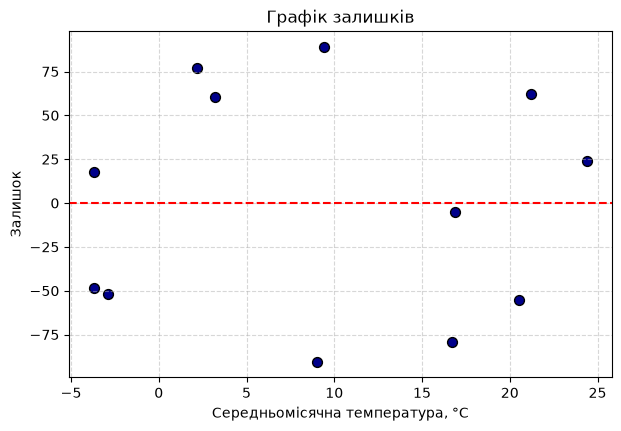

In [3]:
city_data["залишок"] = city_data["споживання_МВтгод"] - city_data["передбачення"]
print(city_data[["місяць", "температура", "споживання_МВтгод", "передбачення", "залишок"]])

ss_res = (city_data["залишок"] ** 2).sum()
ss_tot = ((city_data["споживання_МВтгод"] - city_data["споживання_МВтгод"].mean()) ** 2).sum()
r_squared = 1 - ss_res / ss_tot
print(f"\nКоефіцієнт детермінації R²: {r_squared:.4f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(city_data["температура"], city_data["залишок"], color="darkblue", s=50, edgecolor="black")
ax.axhline(0, color="red", linestyle="--", linewidth=1.5)
ax.set_xlabel("Середньомісячна температура, °C")
ax.set_ylabel("Залишок")
ax.set_title("Графік залишків")
ax.grid(True, linestyle="--", alpha=0.5)
plt.show()